# 5. Results analysis (data v2, final)

Reads the saved results of notebook 3 (imputation accuracy) and notebook 4 (downstream), plus the v2 dataset. No experiment is re-run.

| Section | Report | Question |
|---|---|---|
| 2 | 4.1 Dataset overview | — |
| 3 | 4.2 Mechanism validation | Did the injection work as designed? |
| 4 | 4.3 Imputation accuracy | RQ1 |
| 5 | 4.4–4.5 Downstream performance | RQ2 |
| 6 | 4.6 Statistical tests on AUC | RQ3 |
| 7 | 4.7 Accuracy vs downstream | Discussion |

All tables are saved to `results/final_tables/`, figures to `results/figures/`.
Run with **Restart Kernel and Run All**.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import friedmanchisquare, wilcoxon, pearsonr, spearmanr, t as t_dist

BASE = Path("/Users/sivhoung/Desktop/Year 4 intern project/Project code ")
DATA_PATH = BASE / "dataset" / "processed dataset" / "final_df_(distance)_v2.parquet"
RESULTS_DIR = BASE / "results"
TABLE_DIR = RESULTS_DIR / "final_tables"
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
SUFFIX = "datav2"

METHODS = ["Mean", "Median", "KNN", "MICE"]
MECHANISMS = ["MCAR", "MAR", "MNAR"]
RATES = [0.1, 0.3, 0.5]
KEYS = ["mechanism", "missing_rate", "method"]
TARGET = "total_freight_value"
AUXILIARY = "total_product_weight_g"
FEATURES = [
    "total_price", "total_freight_value", "total_product_weight_g",
    "average_product_length_cm", "average_product_height_cm",
    "item_count", "max_payment_installments", "average_distance_km",
]

# one fixed colour + marker per method (colour never carries meaning alone)
STYLE = {
    "Mean":   dict(color="#2a78d6", marker="o"),
    "Median": dict(color="#eb6834", marker="s"),
    "KNN":    dict(color="#1baf7a", marker="^"),
    "MICE":   dict(color="#eda100", marker="D"),
}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

In [2]:
def holm(p_values):
    """Holm step-down adjusted p-values."""
    p = np.asarray(p_values, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adj = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj


def kendall_w(chi2, n_blocks, k):
    """Kendall's coefficient of concordance from the Friedman statistic."""
    return chi2 / (n_blocks * (k - 1))


def friedman_block(wide, lower_is_better):
    """Friedman test on a blocks x methods table; returns stat, p, W and mean ranks (1 = best)."""
    stat, p = friedmanchisquare(*[wide[m].to_numpy() for m in METHODS])
    if np.isnan(p):
        stat, p = 0.0, 1.0
    ranks = wide.rank(axis=1, ascending=lower_is_better).mean()
    return {
        "n_blocks": len(wide), "friedman_chi2": stat, "p": p,
        "kendall_W": kendall_w(stat, len(wide), len(METHODS)),
        "best_mean_rank": ranks.idxmin(),
        **{f"rank_{m}": ranks[m] for m in METHODS},
    }


def friedman_by_scenario(raw, metric, lower_is_better):
    wide_all = raw.pivot_table(index=["mechanism", "missing_rate", "seed"], columns="method", values=metric)[METHODS]
    rows = []
    for (mech, rate), g in wide_all.groupby(level=["mechanism", "missing_rate"]):
        rows.append({"mechanism": mech, "missing_rate": rate, **friedman_block(g, lower_is_better)})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p"])
    out["significant_holm"] = out["p_holm"] < 0.05
    out["mechanism"] = pd.Categorical(out["mechanism"], MECHANISMS, ordered=True)
    return out.sort_values(["mechanism", "missing_rate"]).reset_index(drop=True), wide_all


def pairwise_wilcoxon(wide):
    rows = []
    for i, a in enumerate(METHODS):
        for b in METHODS[i + 1:]:
            d = wide[a].to_numpy() - wide[b].to_numpy()
            try:
                _, p = wilcoxon(wide[a], wide[b])
            except ValueError:
                p = 1.0
            rows.append({"method_a": a, "method_b": b, "mean_diff_a_minus_b": d.mean(),
                         "share_a_higher": (d > 0).mean(), "wilcoxon_p": p})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["wilcoxon_p"])
    return out


def mean_std_table(df, mean_col, std_col, decimals):
    t = df.copy()
    fmt = f"{{:.{decimals}f}}"
    t["value"] = t[mean_col].map(fmt.format) + " ± " + t[std_col].map(fmt.format)
    return (
        t.pivot_table(index="method", columns=["mechanism", "missing_rate"], values="value", aggfunc="first")
        .reindex(index=METHODS, columns=pd.MultiIndex.from_product([MECHANISMS, RATES]))
    )

## 1. Load results and check completeness

In [3]:
imp_raw = pd.read_csv(RESULTS_DIR / f"imputation_results_raw_{SUFFIX}.csv")
imp_summary = pd.read_csv(RESULTS_DIR / f"imputation_results_summary_{SUFFIX}.csv")
ds_raw = pd.read_csv(RESULTS_DIR / f"downstream_results_raw_{SUFFIX}.csv")
ds_summary = pd.read_csv(RESULTS_DIR / f"downstream_results_summary_{SUFFIX}.csv")
ds_friedman_nb4 = pd.read_csv(RESULTS_DIR / f"downstream_friedman_by_scenario_{SUFFIX}.csv")
ds_posthoc_nb4 = pd.read_csv(RESULTS_DIR / f"downstream_pooled_posthoc_{SUFFIX}.csv")

for frame in (imp_raw, imp_summary, ds_raw, ds_summary, ds_friedman_nb4):
    frame["missing_rate"] = frame["missing_rate"].round(2)

n_imp_seeds, n_ds_seeds = imp_raw["seed"].nunique(), ds_raw["seed"].nunique()
assert len(imp_raw) == n_imp_seeds * 36
assert len(imp_summary) == 36
assert len(ds_raw) == n_ds_seeds * (2 + 36)
assert imp_raw[["MAE", "RMSE"]].notna().all().all()
assert ds_raw[["accuracy", "precision", "recall", "f1", "roc_auc"]].notna().all().all()

print("imputation seeds:", sorted(imp_raw["seed"].unique()))
print("downstream seeds:", sorted(ds_raw["seed"].unique()))
print("same seed set:", set(imp_raw["seed"]) == set(ds_raw["seed"]))
print("OK: all checks passed")

imputation seeds: [np.int64(1), np.int64(7), np.int64(21), np.int64(42), np.int64(100)]
downstream seeds: [np.int64(1), np.int64(7), np.int64(21), np.int64(42), np.int64(100)]
same seed set: True
OK: all checks passed


## 2. Dataset overview (report 4.1, Table 2)

In [4]:
df = pd.read_parquet(DATA_PATH)
model_df = df[["order_id", *FEATURES, "is_delayed"]].dropna().copy()
model_df["is_delayed"] = model_df["is_delayed"].astype(int)

M, N = len(df), len(model_df)
print(f"M (orders after the data-quality rule): {M}")
print(f"N (complete cases used in experiments): {N}")
print(f"removed by complete-case filter: {M - N} ({(M - N) / M:.2%})")
print()
print("missing values per column before the complete-case filter:")
print(df[FEATURES + ["is_delayed"]].isna().sum().to_string())
print()
counts = model_df["is_delayed"].value_counts().sort_index()
print(f"not delayed (0): {counts[0]} ({counts[0] / N:.2%})")
print(f"delayed     (1): {counts[1]} ({counts[1] / N:.2%})")

M (orders after the data-quality rule): 99418
N (complete cases used in experiments): 95959
removed by complete-case filter: 3459 (3.48%)

missing values per column before the complete-case filter:
total_price                   775
total_freight_value           775
total_product_weight_g        791
average_product_length_cm     791
average_product_height_cm     791
item_count                    775
max_payment_installments        1
average_distance_km          1265
is_delayed                   2965

not delayed (0): 89470 (93.24%)
delayed     (1): 6489 (6.76%)


In [5]:
desc = model_df[FEATURES].describe().T[["mean", "std", "50%", "min", "max"]]
desc.columns = ["Mean", "Std", "Median", "Min", "Max"]
desc.to_csv(TABLE_DIR / "table2_descriptive_stats.csv")
desc.round(2)

,Mean,Std,Median,Min,Max
total_price,137.07,209.24,86.00,0.85,13440.00
total_freight_value,22.78,21.58,17.16,0.00,1794.96
total_product_weight_g,2384.54,4767.85,750.00,0.00,184400.00
average_product_length_cm,30.08,16.04,25.00,7.00,105.00
average_product_height_cm,16.46,13.25,13.00,2.00,105.00
item_count,1.14,0.54,1.00,1.00,21.00
max_payment_installments,2.93,2.71,2.00,0.00,24.00
average_distance_km,600.45,592.10,433.84,0.00,3399.19


## 3. Mechanism validation (report 4.2)

Reproduces the injection of notebook 3 (seed 42, full complete-case dataset) and compares the missing and observed groups.
For MAR the freight value is shown too: because weight and freight are correlated, the missing group should also have higher freight, which explains why mean/median imputation under-estimates under MAR.

In [6]:
def inject(data, mechanism, rate, seed):
    out = data.copy()
    rng = np.random.default_rng(seed)
    n_missing = int(len(out) * rate)
    if mechanism == "MCAR":
        idx = rng.choice(out.index, size=n_missing, replace=False)
    else:
        driver = AUXILIARY if mechanism == "MAR" else TARGET
        w = out[driver].rank(pct=True).to_numpy() + 0.01
        idx = rng.choice(out.index, size=n_missing, replace=False, p=w / w.sum())
    out.loc[idx, TARGET] = np.nan
    return out


val_data = df[["order_id", *FEATURES, "is_delayed"]].dropna().copy()   # same frame as notebook 3
rows = []
for mech in MECHANISMS:
    for rate in RATES:
        miss = inject(val_data, mech, rate, 42)[TARGET].isna()
        rows.append({
            "mechanism": mech, "missing_rate": rate, "actual_rate": miss.mean(),
            "weight_missing": val_data.loc[miss, AUXILIARY].mean(),
            "weight_observed": val_data.loc[~miss, AUXILIARY].mean(),
            "freight_missing": val_data.loc[miss, TARGET].mean(),
            "freight_observed": val_data.loc[~miss, TARGET].mean(),
        })
validation = pd.DataFrame(rows)
validation.to_csv(TABLE_DIR / "table_mechanism_validation.csv", index=False)
validation.round(2)

,mechanism,missing_rate,actual_rate,weight_missing,weight_observed,freight_missing,freight_observed
0,MCAR,0.1,0.1,2301.88,2393.72,22.21,22.84
1,MCAR,0.3,0.3,2361.60,2394.37,22.58,22.86
2,MCAR,0.5,0.5,2366.70,2402.38,22.66,22.89
3,MAR,0.1,0.1,4025.59,2202.22,27.89,22.21
4,MAR,0.3,0.3,3689.24,1825.40,26.76,21.07
5,MAR,0.5,0.5,3432.44,1336.66,25.99,19.56
6,MNAR,0.1,0.1,3519.52,2258.44,30.53,21.92
7,MNAR,0.3,0.3,3290.95,1996.09,29.26,20.00
8,MNAR,0.5,0.5,3119.59,1649.51,28.00,17.55


## 4. RQ1 — Imputation accuracy (report 4.3)

In [7]:
mae_table = mean_std_table(imp_summary, "MAE_mean", "MAE_std", 2)
mae_table.to_csv(TABLE_DIR / "table_mae_mean_std.csv")
mae_table

MCAR                                       MAR                                      MNAR                            
                 0.1           0.3           0.5           0.1           0.3           0.5           0.1           0.3           0.5
method                                                                                                                              
Mean    11.23 ± 0.21  11.35 ± 0.08  11.36 ± 0.04  13.45 ± 0.28  12.72 ± 0.05  12.06 ± 0.03  13.49 ± 0.17  12.81 ± 0.14  12.40 ± 0.09
Median   9.66 ± 0.27   9.83 ± 0.12   9.84 ± 0.07  13.36 ± 0.28  12.81 ± 0.08  12.43 ± 0.03  14.57 ± 0.20  14.17 ± 0.15  13.60 ± 0.06
KNN      5.06 ± 0.11   5.17 ± 0.06   5.25 ± 0.06   6.96 ± 0.14   6.83 ± 0.05   6.67 ± 0.03   7.47 ± 0.12   7.26 ± 0.08   7.07 ± 0.04
MICE     5.82 ± 0.10   5.90 ± 0.05   5.93 ± 0.06   7.89 ± 0.16   7.57 ± 0.04   7.26 ± 0.08   8.15 ± 0.11   7.80 ± 0.08   7.36 ± 0.03

In [8]:
rmse_table = mean_std_table(imp_summary, "RMSE_mean", "RMSE_std", 2)
rmse_table.to_csv(TABLE_DIR / "table_rmse_mean_std.csv")
rmse_table

MCAR                                       MAR                                      MNAR                            
                 0.1           0.3           0.5           0.1           0.3           0.5           0.1           0.3           0.5
method                                                                                                                              
Mean    20.24 ± 1.35  22.09 ± 1.31  21.74 ± 0.60  26.33 ± 1.18  27.40 ± 0.72  26.35 ± 0.38  28.23 ± 0.91  28.61 ± 1.04  27.44 ± 0.52
Median  20.94 ± 1.39  22.79 ± 1.29  22.46 ± 0.61  27.87 ± 1.16  28.70 ± 0.69  27.48 ± 0.36  30.14 ± 0.88  30.24 ± 0.99  28.47 ± 0.50
KNN     11.78 ± 0.82  13.53 ± 1.58  13.22 ± 0.88  15.15 ± 0.63  16.88 ± 0.97  15.98 ± 0.54  16.34 ± 0.62  17.77 ± 1.34  16.67 ± 0.67
MICE    11.70 ± 0.51  13.64 ± 1.32  13.28 ± 0.76  15.66 ± 0.73  16.97 ± 0.84  15.94 ± 0.44  16.58 ± 0.44  17.47 ± 1.12  16.19 ± 0.67

In [9]:
# Relative MAE improvement over mean imputation (%), and RMSE/MAE ratio
mean_mae = imp_summary[imp_summary["method"] == "Mean"].set_index(["mechanism", "missing_rate"])["MAE_mean"]
imp = imp_summary.copy()
imp["improvement_vs_mean_pct"] = 100 * (imp.set_index(["mechanism", "missing_rate"]).index.map(mean_mae) - imp["MAE_mean"]) / imp.set_index(["mechanism", "missing_rate"]).index.map(mean_mae)
imp["rmse_mae_ratio"] = imp["RMSE_mean"] / imp["MAE_mean"]

improvement = imp.pivot_table(index="method", columns=["mechanism", "missing_rate"], values="improvement_vs_mean_pct").reindex(index=METHODS, columns=pd.MultiIndex.from_product([MECHANISMS, RATES]))
improvement.to_csv(TABLE_DIR / "table_mae_improvement_vs_mean_pct.csv")
print("MAE reduction relative to mean imputation (%):")
improvement.round(1)

MAE reduction relative to mean imputation (%):


MCAR               MAR              MNAR            
         0.1   0.3   0.5   0.1   0.3   0.5   0.1   0.3   0.5
method                                                      
Mean     0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
Median  13.9  13.4  13.4   0.7  -0.7  -3.1  -8.0 -10.6  -9.6
KNN     54.9  54.5  53.8  48.2  46.3  44.7  44.6  43.3  43.0
MICE    48.1  48.0  47.8  41.3  40.5  39.8  39.5  39.1  40.6

In [10]:
ratio = imp.pivot_table(index="method", columns=["mechanism", "missing_rate"], values="rmse_mae_ratio").reindex(index=METHODS, columns=pd.MultiIndex.from_product([MECHANISMS, RATES]))
print("RMSE / MAE ratio (higher = more of the error comes from a few large errors):")
ratio.round(2)

RMSE / MAE ratio (higher = more of the error comes from a few large errors):


MCAR               MAR              MNAR            
         0.1   0.3   0.5   0.1   0.3   0.5   0.1   0.3   0.5
method                                                      
Mean    1.80  1.95  1.91  1.96  2.15  2.18  2.09  2.23  2.21
Median  2.17  2.32  2.28  2.09  2.24  2.21  2.07  2.13  2.09
KNN     2.33  2.62  2.52  2.18  2.47  2.40  2.19  2.45  2.36
MICE    2.01  2.31  2.24  1.98  2.24  2.20  2.03  2.24  2.20

In [11]:
# Overall ranking (mean over all 9 scenarios)
overall = imp.groupby("method")[["MAE_mean", "RMSE_mean"]].mean().reindex(METHODS)
overall["rank_MAE"] = overall["MAE_mean"].rank()
overall.round(3)

,MAE_mean,RMSE_mean,rank_MAE
method,,,
Mean,12.319,25.381,4.0
Median,12.252,26.567,3.0
KNN,6.416,15.259,1.0
MICE,7.077,15.270,2.0


### 4.1 Friedman test on MAE (lower = better)

In [12]:
mae_friedman, mae_wide = friedman_by_scenario(imp_raw, "MAE", lower_is_better=True)
mae_friedman.to_csv(TABLE_DIR / "table_friedman_mae_by_scenario.csv", index=False)
print("significant after Holm:", int(mae_friedman["significant_holm"].sum()), "of 9")
mae_friedman.round(4)

significant after Holm: 9 of 9


,mechanism,missing_rate,n_blocks,friedman_chi2,p,kendall_W,best_mean_rank,rank_Mean,rank_Median,rank_KNN,rank_MICE,p_holm,significant_holm
0,MCAR,0.1,5,15.0,0.0018,1.0,KNN,4.0,3.0,1.0,2.0,0.0163,True
1,MCAR,0.3,5,15.0,0.0018,1.0,KNN,4.0,3.0,1.0,2.0,0.0163,True
2,MCAR,0.5,5,15.0,0.0018,1.0,KNN,4.0,3.0,1.0,2.0,0.0163,True
3,MAR,0.1,5,15.0,0.0018,1.0,KNN,4.0,3.0,1.0,2.0,0.0163,True
4,MAR,0.3,5,15.0,0.0018,1.0,KNN,3.0,4.0,1.0,2.0,0.0163,True
5,MAR,0.5,5,15.0,0.0018,1.0,KNN,3.0,4.0,1.0,2.0,0.0163,True
6,MNAR,0.1,5,15.0,0.0018,1.0,KNN,3.0,4.0,1.0,2.0,0.0163,True
7,MNAR,0.3,5,15.0,0.0018,1.0,KNN,3.0,4.0,1.0,2.0,0.0163,True
8,MNAR,0.5,5,15.0,0.0018,1.0,KNN,3.0,4.0,1.0,2.0,0.0163,True


In [13]:
pooled_mae = friedman_block(mae_wide, lower_is_better=True)
print(f"Pooled Friedman on MAE ({pooled_mae['n_blocks']} blocks): chi2 = {pooled_mae['friedman_chi2']:.2f}, "
      f"p = {pooled_mae['p']:.2e}, Kendall's W = {pooled_mae['kendall_W']:.3f}")
print("mean ranks (1 = lowest MAE):", {m: round(pooled_mae[f'rank_{m}'], 2) for m in METHODS})

mae_posthoc = pairwise_wilcoxon(mae_wide)
mae_posthoc.to_csv(TABLE_DIR / "table_posthoc_mae.csv", index=False)
mae_posthoc.round(4)

Pooled Friedman on MAE (45 blocks): chi2 = 121.67, p = 3.38e-26, Kendall's W = 0.901
mean ranks (1 = lowest MAE): {'Mean': np.float64(3.44), 'Median': np.float64(3.56), 'KNN': np.float64(1.0), 'MICE': np.float64(2.0)}


,method_a,method_b,mean_diff_a_minus_b,share_a_higher,wilcoxon_p,p_holm
0,Mean,Median,0.0670,0.4444,0.3641,0.3641
1,Mean,KNN,5.9032,1.0000,0.0000,0.0000
2,Mean,MICE,5.2426,1.0000,0.0000,0.0000
3,Median,KNN,5.8362,1.0000,0.0000,0.0000
4,Median,MICE,5.1756,1.0000,0.0000,0.0000
5,KNN,MICE,-0.6606,0.0000,0.0000,0.0000


### 4.2 Figure: MAE by mechanism and missing rate

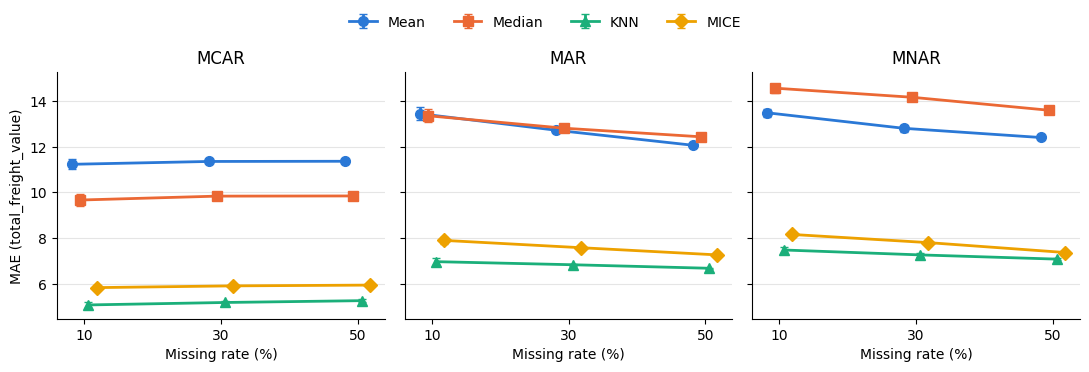

In [14]:
def line_panels(summary, mean_col, std_col, ylabel, fname, baselines=None):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
    for ax, mech in zip(axes, MECHANISMS):
        sub = summary[summary["mechanism"] == mech]
        for j, m in enumerate(METHODS):
            s = sub[sub["method"] == m].sort_values("missing_rate")
            offset = (j - 1.5) * 1.2          # small horizontal dodge so error bars do not overlap
            ax.errorbar(s["missing_rate"] * 100 + offset, s[mean_col], yerr=s[std_col],
                        label=m, lw=2, ms=7, capsize=3, **STYLE[m])
        if baselines is not None:
            ax.axhline(baselines["Full_data"], color="#555555", ls="--", lw=1.2, label="Full data")
            ax.axhline(baselines["Drop_column"], color="#555555", ls=":", lw=1.4, label="Drop column")
        ax.set_title(mech)
        ax.set_xticks([10, 30, 50])
        ax.set_xlabel("Missing rate (%)")
        ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    axes[0].set_ylabel(ylabel)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, 1.04))
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIG_DIR / fname, dpi=300, bbox_inches="tight")
    plt.show()


line_panels(imp_summary, "MAE_mean", "MAE_std", "MAE (total_freight_value)", "fig_rq1_mae.png")

## 5. RQ2 — Downstream performance (report 4.4–4.5)

In [15]:
full = ds_raw[ds_raw["method"] == "Full_data"].set_index("seed")["roc_auc"]
drop = ds_raw[ds_raw["method"] == "Drop_column"].set_index("seed")["roc_auc"]

gap = (full - drop)                      # paired by seed
n = len(gap)
half = t_dist.ppf(0.975, n - 1) * gap.std(ddof=1) / np.sqrt(n)
print(f"Full_data   AUC: {full.mean():.4f} ± {full.std():.4f}")
print(f"Drop_column AUC: {drop.mean():.4f} ± {drop.std():.4f}")
print(f"Delta_max = Full - Drop: {gap.mean():.4f}  95% CI [{gap.mean() - half:.4f}, {gap.mean() + half:.4f}]  (n = {n} seeds)")
print("per-seed gaps:", gap.round(4).to_dict())

baselines = ds_summary[ds_summary["mechanism"] == "Baseline"].set_index("method")
baselines[["auc_mean", "auc_std", "f1_mean", "f1_std", "recall_mean", "precision_mean", "accuracy_mean"]].round(4)

Full_data   AUC: 0.6145 ± 0.0069
Drop_column AUC: 0.6041 ± 0.0067
Delta_max = Full - Drop: 0.0104  95% CI [0.0012, 0.0196]  (n = 5 seeds)
per-seed gaps: {42: -0.0004, 1: 0.0168, 7: 0.0077, 21: 0.0179, 100: 0.0101}


,auc_mean,auc_std,f1_mean,f1_std,recall_mean,precision_mean,accuracy_mean
method,,,,,,,
Drop_column,0.6041,0.0067,0.1580,0.0020,0.4923,0.0941,0.6452
Full_data,0.6145,0.0069,0.1613,0.0045,0.5217,0.0954,0.6330


In [16]:
auc_table = mean_std_table(ds_summary[ds_summary["mechanism"] != "Baseline"], "auc_mean", "auc_std", 4)
auc_table.to_csv(TABLE_DIR / "table_auc_mean_std.csv")
auc_table

MCAR                                                MAR                                               MNAR                                  
                    0.1              0.3              0.5              0.1              0.3              0.5              0.1              0.3              0.5
method                                                                                                                                                         
Mean    0.6138 ± 0.0047  0.6120 ± 0.0051  0.6098 ± 0.0049  0.6120 ± 0.0047  0.6142 ± 0.0050  0.6087 ± 0.0052  0.6126 ± 0.0064  0.6127 ± 0.0037  0.6102 ± 0.0067
Median  0.6143 ± 0.0053  0.6101 ± 0.0050  0.6093 ± 0.0051  0.6131 ± 0.0053  0.6115 ± 0.0067  0.6086 ± 0.0023  0.6133 ± 0.0065  0.6106 ± 0.0060  0.6094 ± 0.0069
KNN     0.6117 ± 0.0043  0.6108 ± 0.0056  0.6107 ± 0.0045  0.6119 ± 0.0050  0.6123 ± 0.0041  0.6067 ± 0.0059  0.6128 ± 0.0048  0.6103 ± 0.0062  0.6091 ± 0.0058
MICE    0.6129 ± 0.0059  0.6090 ± 0.0051  0.6090 ± 0.0049  0.6119 ± 0.0052  0.6105 ± 0.0064  0.6077 ± 0.0069  0.6134 ± 0.0036  0.6109 ± 0.0045  0.6063 ± 0.0051

In [17]:
# Recovery ratio = (AUC_method - AUC_drop) / (AUC_full - AUC_drop), computed from the mean AUCs.
# (Per-seed ratios are unstable: for seed 42 the Full-Drop gap is about 0, so the denominator explodes.)
auc_means = ds_summary[ds_summary["mechanism"] != "Baseline"].copy()
auc_means["recovery_of_means"] = (auc_means["auc_mean"] - drop.mean()) / (full.mean() - drop.mean())
recovery = auc_means.pivot_table(index="method", columns=["mechanism", "missing_rate"], values="recovery_of_means").reindex(index=METHODS, columns=pd.MultiIndex.from_product([MECHANISMS, RATES]))
recovery.to_csv(TABLE_DIR / "table_recovery_ratio.csv")
print("Recovery ratio (1 = as good as full data, 0 = as good as dropping the feature):")
recovery.round(2)

Recovery ratio (1 = as good as full data, 0 = as good as dropping the feature):


MCAR               MAR              MNAR            
         0.1   0.3   0.5   0.1   0.3   0.5   0.1   0.3   0.5
method                                                      
Mean    0.94  0.76  0.55  0.76  0.98  0.44  0.82  0.83  0.59
Median  0.98  0.58  0.50  0.87  0.72  0.43  0.89  0.63  0.51
KNN     0.73  0.64  0.64  0.75  0.79  0.25  0.84  0.59  0.48
MICE    0.85  0.47  0.47  0.75  0.62  0.35  0.89  0.66  0.21

In [18]:
# Range of AUC between methods vs. seed-to-seed variation, per scenario
g = ds_summary[ds_summary["mechanism"] != "Baseline"].groupby(["mechanism", "missing_rate"])
spread = pd.DataFrame({
    "auc_range_between_methods": g["auc_mean"].max() - g["auc_mean"].min(),
    "mean_auc_std_across_seeds": g["auc_std"].mean(),
}).reset_index()
spread["range_larger_than_std"] = spread["auc_range_between_methods"] > spread["mean_auc_std_across_seeds"]
spread.round(4)

,mechanism,missing_rate,auc_range_between_methods,mean_auc_std_across_seeds,range_larger_than_std
0,MAR,0.1,0.0012,0.0051,False
1,MAR,0.3,0.0037,0.0056,False
2,MAR,0.5,0.0020,0.0051,False
3,MCAR,0.1,0.0027,0.0051,False
4,MCAR,0.3,0.0029,0.0052,False
5,MCAR,0.5,0.0017,0.0049,False
6,MNAR,0.1,0.0008,0.0053,False
7,MNAR,0.3,0.0025,0.0051,False
8,MNAR,0.5,0.0040,0.0061,False


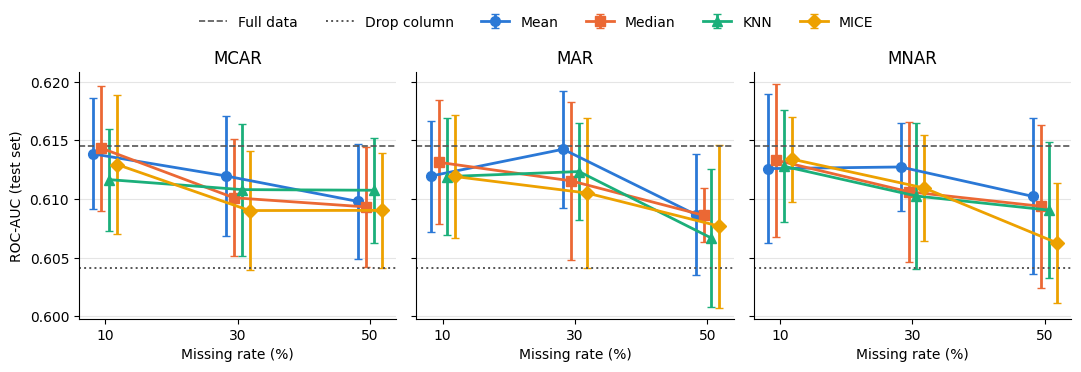

In [19]:
line_panels(ds_summary[ds_summary["mechanism"] != "Baseline"], "auc_mean", "auc_std", "ROC-AUC (test set)",
            "fig_rq2_auc.png", baselines={"Full_data": full.mean(), "Drop_column": drop.mean()})

## 6. RQ3 — Statistical tests on ROC-AUC (report 4.6)

In [20]:
auc_friedman, auc_wide = friedman_by_scenario(ds_raw[ds_raw["mechanism"] != "Baseline"], "roc_auc", lower_is_better=False)
auc_friedman.to_csv(TABLE_DIR / "table_friedman_auc_by_scenario.csv", index=False)

# must agree with notebook 4
chk = auc_friedman.astype({"mechanism": str}).merge(ds_friedman_nb4, on=["mechanism", "missing_rate"], suffixes=("", "_nb4"))
assert np.allclose(chk["p"], chk["p_nb4"].fillna(1.0)) and np.allclose(chk["p_holm"], chk["p_holm_nb4"])
print("OK: identical to notebook 4")
print("significant after Holm:", int(auc_friedman["significant_holm"].sum()), "of 9")
auc_friedman.round(4)

OK: identical to notebook 4
significant after Holm: 0 of 9


,mechanism,missing_rate,n_blocks,friedman_chi2,p,kendall_W,best_mean_rank,rank_Mean,rank_Median,rank_KNN,rank_MICE,p_holm,significant_holm
0,MCAR,0.1,5,1.08,0.7819,0.072,Median,2.6,2.0,2.8,2.6,1.0000,False
1,MCAR,0.3,5,6.36,0.0954,0.424,Mean,1.6,2.6,2.2,3.6,0.8582,False
2,MCAR,0.5,5,0.36,0.9484,0.024,Mean,2.4,2.4,2.4,2.8,1.0000,False
3,MAR,0.1,5,0.36,0.9484,0.024,Median,2.6,2.2,2.6,2.6,1.0000,False
4,MAR,0.3,5,4.92,0.1777,0.328,Mean,1.6,2.2,3.0,3.2,1.0000,False
5,MAR,0.5,5,3.96,0.2658,0.264,Mean,1.8,2.4,3.4,2.4,1.0000,False
6,MNAR,0.1,5,0.36,0.9484,0.024,MICE,2.6,2.6,2.6,2.2,1.0000,False
7,MNAR,0.3,5,1.08,0.7819,0.072,Mean,2.2,2.4,3.0,2.4,1.0000,False
8,MNAR,0.5,5,2.28,0.5164,0.152,Median,2.4,2.0,2.4,3.2,1.0000,False


In [21]:
pooled_auc = friedman_block(auc_wide, lower_is_better=False)
print(f"Pooled Friedman on AUC ({pooled_auc['n_blocks']} blocks): chi2 = {pooled_auc['friedman_chi2']:.2f}, "
      f"p = {pooled_auc['p']:.4f}, Kendall's W = {pooled_auc['kendall_W']:.3f}")
print("mean ranks (1 = highest AUC):", {m: round(pooled_auc[f'rank_{m}'], 2) for m in METHODS})

auc_posthoc = pairwise_wilcoxon(auc_wide)
auc_posthoc.to_csv(TABLE_DIR / "table_posthoc_auc.csv", index=False)
auc_posthoc.round(4)

Pooled Friedman on AUC (45 blocks): chi2 = 6.68, p = 0.0828, Kendall's W = 0.049
mean ranks (1 = highest AUC): {'Mean': np.float64(2.2), 'Median': np.float64(2.31), 'KNN': np.float64(2.71), 'MICE': np.float64(2.78)}


,method_a,method_b,mean_diff_a_minus_b,share_a_higher,wilcoxon_p,p_holm
0,Mean,Median,0.0006,0.5333,0.2476,0.7428
1,Mean,KNN,0.0011,0.6444,0.0426,0.2128
2,Mean,MICE,0.0016,0.6222,0.0173,0.1037
3,Median,KNN,0.0005,0.6000,0.4464,0.8929
4,Median,MICE,0.0010,0.6222,0.1200,0.4801
5,KNN,MICE,0.0005,0.5333,0.7038,0.8929


## 7. Imputation accuracy vs downstream performance (report 4.7)

Seeds are the same, but the injected rows are not (notebook 3 injects into the full dataset, notebook 4 into the training split only), so MAE and AUC cannot be paired by seed. The comparison uses the 36 scenario × method means.
Expected direction if accuracy carried over: lower MAE → higher AUC (negative correlation).

In [22]:
comparison = imp_summary[KEYS + ["MAE_mean"]].merge(
    ds_summary[KEYS + ["auc_mean", "auc_std"]], on=KEYS, validate="one_to_one")
assert len(comparison) == 36

r_p, p_p = pearsonr(comparison["MAE_mean"], comparison["auc_mean"])
r_s, p_s = spearmanr(comparison["MAE_mean"], comparison["auc_mean"])
print(f"Pooled (36 points):        Pearson r = {r_p:.3f} (p = {p_p:.3f}) | Spearman rho = {r_s:.3f} (p = {p_s:.3f})")

grp = comparison.groupby(["mechanism", "missing_rate"])
mae_c = comparison["MAE_mean"] - grp["MAE_mean"].transform("mean")
auc_c = comparison["auc_mean"] - grp["auc_mean"].transform("mean")
r_w, p_w = pearsonr(mae_c, auc_c)
rho_w, p_ws = spearmanr(mae_c, auc_c)
print(f"Within scenario (centred): Pearson r = {r_w:.3f} (p = {p_w:.3f}) | Spearman rho = {rho_w:.3f} (p = {p_ws:.3f})")

Pooled (36 points):        Pearson r = 0.261 (p = 0.124) | Spearman rho = 0.244 (p = 0.152)
Within scenario (centred): Pearson r = 0.494 (p = 0.002) | Spearman rho = 0.330 (p = 0.050)


In [23]:
rows = []
for (mech, rate), g in comparison.groupby(["mechanism", "missing_rate"]):
    rho, _ = spearmanr(g["MAE_mean"], g["auc_mean"])
    rows.append({
        "mechanism": mech, "missing_rate": rate, "rho_MAE_vs_AUC": rho,
        "best_by_MAE": g.loc[g["MAE_mean"].idxmin(), "method"],
        "best_by_AUC": g.loc[g["auc_mean"].idxmax(), "method"],
        "auc_range": g["auc_mean"].max() - g["auc_mean"].min(),
        "mean_auc_std": g["auc_std"].mean(),
    })
rank_df = pd.DataFrame(rows)
rank_df["same_best"] = rank_df["best_by_MAE"] == rank_df["best_by_AUC"]
rank_df["mechanism"] = pd.Categorical(rank_df["mechanism"], MECHANISMS, ordered=True)
rank_df = rank_df.sort_values(["mechanism", "missing_rate"]).reset_index(drop=True)
rank_df.to_csv(TABLE_DIR / "table_mae_vs_auc_rank_agreement.csv", index=False)
print("best-MAE method = best-AUC method in", int(rank_df["same_best"].sum()), "of 9 scenarios")
print("mean within-scenario rho:", round(rank_df["rho_MAE_vs_AUC"].mean(), 3))
rank_df.round(4)

best-MAE method = best-AUC method in 1 of 9 scenarios
mean within-scenario rho: 0.4


,mechanism,missing_rate,rho_MAE_vs_AUC,best_by_MAE,best_by_AUC,auc_range,mean_auc_std,same_best
0,MCAR,0.1,0.8,KNN,Median,0.0027,0.0051,False
1,MCAR,0.3,0.4,KNN,Mean,0.0029,0.0052,False
2,MCAR,0.5,-0.2,KNN,KNN,0.0017,0.0049,True
3,MAR,0.1,0.8,KNN,Median,0.0012,0.0051,False
4,MAR,0.3,0.0,KNN,Mean,0.0037,0.0056,False
5,MAR,0.5,0.8,KNN,Mean,0.0020,0.0051,False
6,MNAR,0.1,0.0,KNN,MICE,0.0008,0.0053,False
7,MNAR,0.3,0.4,KNN,Mean,0.0025,0.0051,False
8,MNAR,0.5,0.6,KNN,Mean,0.0040,0.0061,False
